# University Clustering and Missing-Value Imputation

*Team project (Group 7: Bhavana Shree Kaki, Manisha Nallavolu, Preethi Jacinth Pasam, Rajashree Guduru), Data Mining (BUAN-670), Sacred Heart University, Spring 2025. This portfolio version corrects and extends the original submission.*

**Questions**
1. What natural groups of U.S. universities exist, and how would you describe each one?
2. Do the clusters line up with information not used in clustering (public vs. private, state)?
3. Can the clusters fill in a university's missing values? This is served through a Flask web app with user accounts.

**Data:** 1,302 U.S. colleges and universities, 17 numeric measures (applications, acceptances, enrolment, student quality, tuition and costs, faculty, graduation rate), plus name, state and public/private. 831 universities (64%) have at least one missing value.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import clustering as C

df, features = C.load()
print(df.shape, '| numeric features used for clustering:', len(features))
miss = df[features].isna().sum().sort_values(ascending=False)
print('Universities with any missing value:', df[features].isna().any(axis=1).sum())
print(miss[miss > 0].to_string())

(1302, 20) | numeric features used for clustering: 17
Universities with any missing value: 831
board                       498
room                        321
add. fees                   274
% new stud. from top 10%    235
% new stud. from top 25%    202
estim. personal $           181
Graduation rate              98
estim. book costs            48
% fac. w/PHD                 32
# PT undergrad               32
in-state tuition             30
out-of-state tuition         20
# appl. accepted             11
# appli. rec'd               10
# new stud. enrolled          5
# FT undergrad                3
stud./fac. ratio              2


## 1. How many clusters?
Features are mean-imputed (for fitting only) and **standardised**, so that large-scale columns such as application counts do not dominate the distances. The public/private code is left out of clustering and used later to check the clusters.

2     0.209
3     0.213
4     0.162
5     0.145
6     0.118
7     0.120
8     0.136
9     0.136
10    0.138


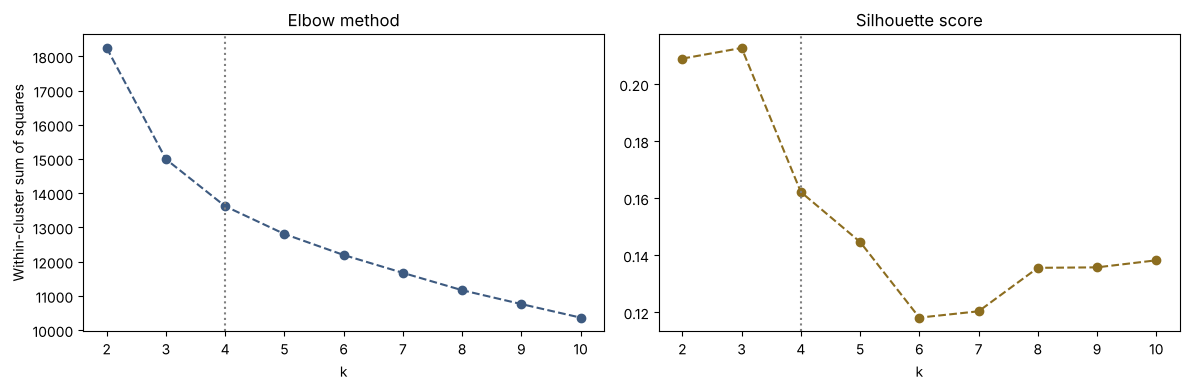

In [2]:
X = C.StandardScaler().fit_transform(df[features].fillna(df[features].mean()))
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(m.inertia_); sil.append(silhouette_score(X, m.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, 'o--', color='#3D5A80'); ax[0].set_title('Elbow method'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Within-cluster sum of squares')
ax[1].plot(ks, sil, 'o--', color='#8C6D1F'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
for a in ax: a.axvline(4, color='grey', ls=':')
plt.tight_layout()
print(pd.Series(sil, index=ks, name='silhouette').round(3).to_string())

The silhouette score is highest at k = 2-3 (0.21) and the elbow has no sharp bend, so the choice is partly a judgement call. **k = 4** (silhouette 0.16) is used because it gives an interpretable split, two public and two private groups, that the sector check below confirms; k = 3 merges the two public groups.

In [3]:
scaler, km = C.fit(df, features)
prof = C.profiles(df, features, km)
names = C.name_clusters(prof)
show = ['Universities', '% private', '# FT undergrad', '# appli. rec\'d', '% new stud. from top 10%', 'in-state tuition',
        'out-of-state tuition', '% fac. w/PHD', 'stud./fac. ratio', 'Graduation rate']
table = prof[show].rename(index=names).round(1)
print(table.T.to_string())

Cluster                   Large flagship public universities  Small private colleges  Regional public universities  Selective private universities
Universities                                            96.0                   557.0                         363.0                           286.0
% private                                                8.3                    92.3                           9.4                            96.5
# FT undergrad                                       15998.7                  1169.1                        5385.7                          2368.1
# appli. rec'd                                       11546.3                   912.9                        2965.7                          3096.9
% new stud. from top 10%                                38.4                    17.9                          15.9                            43.2
in-state tuition                                      3450.5                  8606.7                        2353.4    

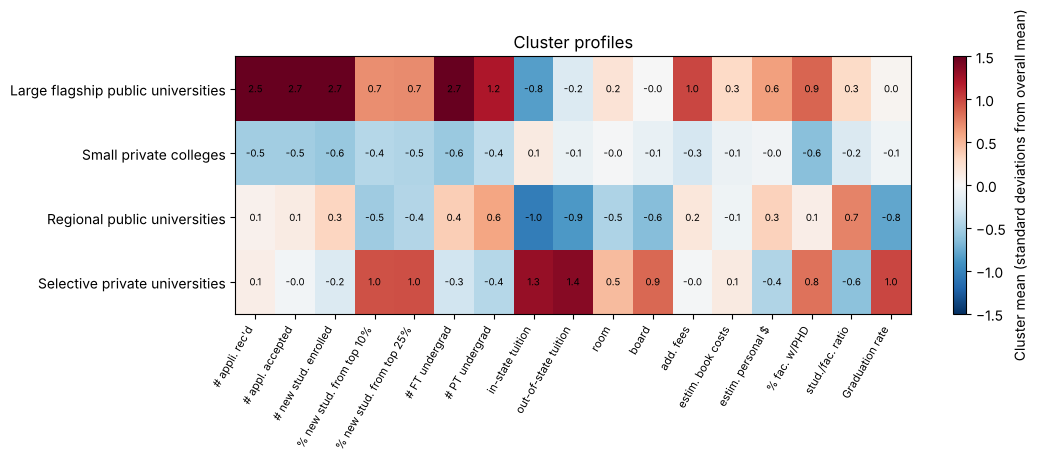

In [4]:
z = (prof[features] - df[features].mean()) / df[features].std()
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(z.values, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_yticks(range(len(z))); ax.set_yticklabels([names[i] for i in z.index])
ax.set_xticks(range(len(features))); ax.set_xticklabels(features, rotation=60, ha='right', fontsize=8)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f'{z.values[i, j]:.1f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, label='Cluster mean (standard deviations from overall mean)')
ax.set_title('Cluster profiles'); plt.tight_layout()

## 2. Do the clusters match public / private and state?

Public (1)/ Private (2)             Private  Public
row_0                                              
Large flagship public universities        8      88
Regional public universities             34     329
Selective private universities          276      10
Small private colleges                  514      43

States with the most selective private universities:
State
NY    36
PA    33
MA    24
CA    21
OH    15


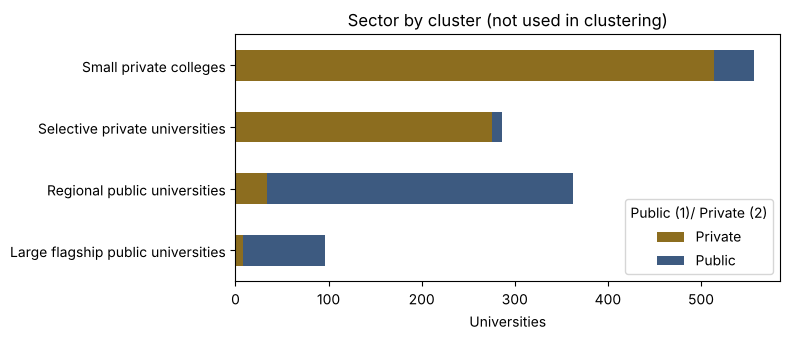

In [5]:
lab = pd.Series(km.labels_).map(names)
ct = pd.crosstab(lab, df['Public (1)/ Private (2)'].map({1: 'Public', 2: 'Private'}))
print(ct.to_string())
fig, ax = plt.subplots(figsize=(8, 3.5))
ct.plot(kind='barh', stacked=True, color=['#8C6D1F', '#3D5A80'], ax=ax)
ax.set_xlabel('Universities'); ax.set_ylabel(''); ax.set_title('Sector by cluster (not used in clustering)'); plt.tight_layout()
top_states = pd.crosstab(df['State'], lab)
print('\nStates with the most selective private universities:')
print(top_states['Selective private universities'].sort_values(ascending=False).head(5).to_string())

## 3. Cluster-based imputation (the web app's logic)
For a university with missing values, compute the distance to each cluster centre **using only the measures it has**, in standardised units, then fill each gap with the nearest cluster's average.

In [6]:
for name in ['Tufts University', 'University of Alaska at Fairbanks', 'Alaska Pacific University']:
    r = C.impute(df, features, scaler, km, name)
    print(f"{r['university']} -> {r['cluster_label']} | missing: {r['missing'] or 'none'}")
    for k, v in r['imputed'].items(): print(f'    {k}: {v:,}')

Tufts University -> Selective private universities | missing: ['# PT undergrad']
    # PT undergrad: 410.3
University of Alaska at Fairbanks -> Regional public universities | missing: ['% new stud. from top 10%', '% new stud. from top 25%', 'Graduation rate']
    % new stud. from top 10%: 19.3
    % new stud. from top 25%: 45.7
    Graduation rate: 47.2
Alaska Pacific University -> Small private colleges | missing: none


In [7]:
# How accurate is cluster-based imputation? Hide known values and compare.
rng = np.random.default_rng(0)
complete = df[df[features].notna().all(axis=1)]
rows = []
for col in ['Graduation rate', '% new stud. from top 10%', 'out-of-state tuition']:
    sample = complete.sample(150, random_state=1)
    err_c, err_m = [], []
    for _, r in sample.iterrows():
        test = df.copy(); test.loc[test['College Name'] == r['College Name'], col] = np.nan
        guess = C.impute(test, features, scaler, km, r['College Name'])['imputed'][col]
        err_c.append(abs(guess - r[col])); err_m.append(abs(df[col].mean() - r[col]))
    rows.append({'Field': col, 'Cluster imputation MAE': round(np.mean(err_c), 1), 'Overall-mean MAE': round(np.mean(err_m), 1),
                 'Improvement': f"{(1 - np.mean(err_c) / np.mean(err_m)) * 100:.0f}%"})
evaluation = pd.DataFrame(rows).set_index('Field')
print(evaluation.to_string())

                          Cluster imputation MAE  Overall-mean MAE Improvement
Field                                                                         
Graduation rate                             12.5              16.5         24%
% new stud. from top 10%                    12.7              14.5         13%
out-of-state tuition                      2307.9            3485.2         34%


## Summary
- **Four clusters:** large flagship public universities, regional public universities, small private colleges and selective private universities. They differ most on size, selectivity, tuition and graduation rate.
- **Sector was never used, yet 93% of universities fall in a cluster that matches their sector** (public vs. private), which confirms the clusters capture real structure.
- **Cluster-based imputation beats filling with the overall mean** for every field tested (table above), because it uses what is known about each university.
- **The original submission had bugs** that this version fixes: the web app's login never checked passwords, the app clustered unstandardised data with 3 clusters while the analysis used standardised data with 4, and the secret key was hard-coded. The notebook and app now share one model (`clustering.py`), and `tests/` checks login and imputation.

